# PGD-MaxEnt — minimal working example

**Notation** (consistent with the notes)

| Symbol | Meaning |
|--------|----------|
| $d$ | dimension |
| $\Sigma^*$ | true covariance ($d\times d$, SPD) |
| $S$ | observed index pairs (lower-triangle convention, diagonal always included) |
| $a_{ij}$ | noisy observation at $(i,j)\in S$ |
| $A$ | $d\times d$ matrix: $A_{ij}=a_{ij}$ on $S$, $0$ elsewhere |
| $K(z)$ | precision matrix parameterised by $z\in \mathbb{R}^{\|S\|}$ |
| $\hat\Sigma$ | estimated covariance $= K(z^*)^{-1}$ |

**Algorithm (two stages)**

- **Stage A (PGD):** find the nearest SPD matrix $\tilde X$ whose entries on $S$ fit $A$  
- **Stage B (MaxEnt):** find the max-entropy completion of $\tilde X|_S$ by solving the dual $\min_z \ell(z) = -\log|K(z)| + \operatorname{tr}(K(z)\,\tilde X)$

## Imports

In [116]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [117]:
def project_psd(X, thresh=1e-12):
    """Project X to the PSD cone by clipping eigenvalues to thresh."""
    vals, vecs = np.linalg.eigh(X)
    return vecs @ np.diag(np.maximum(vals, thresh)) @ vecs.T

## Stage A — Projected Gradient Descent

Minimise the weighted squared-error objective
$$
f(X) = \sum_{(i,j)\in S} \frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2
\quad\text{subject to }X\succeq 0,
$$
where $\tau_{ij}$ is the noise standard deviation for entry $(i,j)$.

**Symmetric rewrite** (for gradient derivation, same value as above):
$$
f(X) = \sum_i \frac{1}{\tau_{ii}^2}(X_{ii}-a_{ii})^2
      + \frac{1}{2}\sum_{(i,j)\in E}\frac{1}{\tau_{ij}^2}(X_{ij}-a_{ij})^2,
$$
where $E=\{(i,j):i\neq j,\,(i,j)\in S\text{ or }(j,i)\in S\}$.  The gradient is
$$
[\nabla f(X)]_{ij} =
\begin{cases}
\dfrac{2}{\tau_{ii}^2}(X_{ii}-a_{ii}) & i=j \\[4pt]
\dfrac{1}{\tau_{ij}^2}(X_{ij}-a_{ij}) & (i,j)\in E \\[4pt]
0 & \text{otherwise.}
\end{cases}
$$

**Weight normalisation.**  Let $w_{ij}=1/\tau_{ij}^2$.  Before running PGD, rescale
$\tilde w_{ij} = w_{ij}/\max_{S} w$.  The normalised objective $\tilde f = f/\max w$
has the same minimiser and makes the step size $\eta$ comparable across problem instances.

In [118]:
def stage_a(A, inds, tau, eta=0.01, n_iters=2000, tol=1e-8, track_kkt=False):
    """
    Inputs
    ------
    A         : (d,d) observation matrix (zero at unobserved entries)
    inds      : (m,2) observed index pairs, lower-triangle including diagonal
    tau       : (m,)  noise std-dev for each entry in inds
    eta       : initial step size
    track_kkt : if True, compute and store KKT diagnostics each iteration
                (requires two eigendecompositions per step — disable for speed)

    Returns
    -------
    X    : (d,d) PSD matrix with X_S ≈ A_S
    hist : list of per-iteration dicts; KKT fields present only if track_kkt=True
    """
    d = A.shape[0]

    # Normalised weights: w̃_k = (1/τ_k²) / max_k(1/τ_k²)
    w = 1.0 / tau ** 2
    w = w / w.max()

    W = np.zeros((d, d))
    W[inds[:, 0], inds[:, 1]] = w
    W[inds[:, 1], inds[:, 0]] = w          # symmetric (no-op for diagonal)
    mask = W > 0

    def objective(X):
        r = X[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
        return np.sum(w * r ** 2)

    # Backtracking line search parameters
    armijo = 0.5    # sufficient decrease constant
    beta   = 0.5    # step size decrease factor on backtrack
    gamma  = 1.05   # step size increase factor after a successful step

    X = project_psd(A.copy())
    hist = []

    for t in range(n_iters):
        # Gradient at current X
        G = np.where(mask, W * (X - A), 0.0)
        G[np.arange(d), np.arange(d)] *= 2
        obj = objective(X)

        # Armijo backtracking line search for PGD.
        # Condition: f(X_new) ≤ f(X) − (armijo/η)‖X_new − X‖²
        for _ in range(50):
            X_new = project_psd(X - eta * G)
            delta = np.linalg.norm(X_new - X, 'fro')
            if objective(X_new) <= obj - armijo * delta ** 2 / eta:
                break
            eta *= beta
            if eta < 1e-14:
                break

        entry = {
            'obj':       obj,
            'delta':     delta,
            'grad_norm': np.linalg.norm(G, 'fro'),
            'eta':       eta,
        }

        if track_kkt:
            # Computed at current X (before the step) where G was evaluated
            entry['min_eig_X']  = np.linalg.eigvalsh(X).min()
            entry['min_eig_G']  = np.linalg.eigvalsh(G).min()
            entry['comp_slack'] = abs(np.sum(G * X))

        hist.append(entry)
        X    = X_new
        eta *= gamma    # modest increase; keeps eta near the local Lipschitz scale

        if delta < tol:
            break

    return X, hist

## Stage B — Maximum Entropy completion

Given the Stage A output $\tilde X$, solve the dual of the max-entropy completion:
$$
\min_{z\in\mathbb{R}^{|S|}} \;\ell(z) = -\log|K(z)| + \operatorname{tr}\bigl(K(z)\,\tilde X\bigr)
$$
Gradient:
$$
\frac{\partial\ell}{\partial z_k} =
\begin{cases}
\tilde X_{ii} - \Sigma_{ii} & i=j \\
2(\tilde X_{ij} - \Sigma_{ij}) & i\neq j
\end{cases},
\qquad \Sigma = K(z)^{-1}.
$$
At the optimum $\hat\Sigma_{ij} = \tilde X_{ij}$ for all $(i,j)\in S$, and $K(z^*)_{ij}=0$ outside $S$.

In [119]:
def build_K(z, inds, d):
    """
    Build the symmetric precision matrix K(z).
    K[i,j] = K[j,i] = z[k]  for (i,j) = inds[k].
    (For diagonal entries the two writes coincide, so K[i,i] = z[k].)
    """
    K = np.zeros((d, d))
    K[inds[:, 0], inds[:, 1]] = z
    K[inds[:, 1], inds[:, 0]] = z
    return K


def stage_b(X_psd, inds, n_iters=500):
    """
    Inputs
    ------
    X_psd  : (d,d) PSD matrix from Stage A  (plays the role of 'a' in the dual)
    inds   : (m,2) observed index pairs

    Returns
    -------
    Sigma_hat : (d,d) max-entropy covariance estimate
    hist      : list of per-iteration dicts:
                  loss            : dual objective -log|K| + tr(K X̃)
                  constraint_viol : rms( Σ̂_S - X̃_S )  (→ 0 at convergence)
                  grad_norm       : ‖∇ℓ(z)‖             (→ 0 at convergence)
                  min_eig_K       : λ_min(K)             (stays > 0 if K remains PD)
    """
    d = X_psd.shape[0]
    rows, cols = inds[:, 0], inds[:, 1]
    diag_mask = rows == cols

    hist = []

    def loss_and_grad(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return 1e15, np.zeros_like(z)
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        mult = np.where(diag_mask, 1.0, 2.0)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        return float(loss), grad

    def callback(z):
        K = build_K(z, inds, d)
        sign, logdet_K = np.linalg.slogdet(K)
        if sign <= 0:
            return
        Sigma = np.linalg.inv(K)
        loss = -logdet_K + np.sum(K * X_psd)
        mult = np.where(diag_mask, 1.0, 2.0)
        grad = mult * (X_psd[rows, cols] - Sigma[rows, cols])
        hist.append({
            'loss':            float(loss),
            'constraint_viol': float(np.sqrt(np.mean((Sigma[rows, cols] - X_psd[rows, cols]) ** 2))),
            'grad_norm':       float(np.linalg.norm(grad)),
            'min_eig_K':       float(np.linalg.eigvalsh(K).min()),
        })

    z0 = np.where(diag_mask, 1.0 / np.maximum(X_psd[rows, cols], 1e-6), 0.0)

    result = minimize(
        loss_and_grad, z0,
        method='L-BFGS-B', jac=True,
        callback=callback,
        options={'maxiter': n_iters, 'ftol': 1e-15, 'gtol': 1e-8},
    )

    K_opt = build_K(result.x, inds, d)
    Sigma_hat = project_psd(np.linalg.inv(K_opt))
    return Sigma_hat, hist

## Full pipeline

In [120]:
def pgd_maxent(A, inds, tau, eta=0.01, pgd_iters=2000, lbfgs_iters=500, tol=1e-8, track_kkt=False):
    """
    Full pipeline.  Returns (Sigma_hat, hist_a, hist_b).
    track_kkt : passed to stage_a; enables KKT diagnostics at extra compute cost.
    """
    print("Stage A: PGD...")
    X_psd, hist_a = stage_a(A, inds, tau, eta=eta, n_iters=pgd_iters, tol=tol, track_kkt=track_kkt)
    r = X_psd[inds[:, 0], inds[:, 1]] - A[inds[:, 0], inds[:, 1]]
    print(f"  {len(hist_a)} iters | obs residual rms = {np.sqrt(np.mean(r**2)):.2e}"
          f" | min eig = {np.linalg.eigvalsh(X_psd).min():.2e}")

    print("Stage B: MaxEnt (L-BFGS)...")
    Sigma_hat, hist_b = stage_b(X_psd, inds, n_iters=lbfgs_iters)
    print(f"  {len(hist_b)} iters | final loss = {hist_b[-1]['loss']:.4e}"
          f" | constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")

    return Sigma_hat, hist_a, hist_b

## Synthetic problem

In [121]:
def make_problem(
    d           = 8,
    n_offdiag   = 12,
    tau_diag    = 0.1,      # noise std-dev for all diagonal entries
    offdiag_mul = 4.0,      # initial off-diagonal τ = tau_diag * offdiag_mul
    decrease_every = 5,     # halve off-diagonal τ after this many measurements
    decrease_by = 2.0,      # multiplicative decrease factor
    seed        = 42,
):
    """
    Returns
    -------
    Sigma_true : (d,d) true covariance
    A          : (d,d) noisy observation matrix (zero at unobserved entries)
    inds       : (m,2) observed pairs, lower-triangle including diagonal
    tau        : (m,)  noise std-dev for each entry in inds
    """
    rng = np.random.default_rng(seed)

    # True covariance
    Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
    eigvals = np.clip(np.exp(rng.standard_normal(d)), 0.1, 10.0)
    Sigma_true = Q @ np.diag(eigvals) @ Q.T

    # Observation index set S
    diag_inds    = [(i, i) for i in range(d)]
    pool         = [(i, j) for i in range(d) for j in range(i + 1, d)]
    chosen       = rng.choice(len(pool), min(n_offdiag, len(pool)), replace=False)
    off_diag_inds = [pool[k] for k in chosen]

    # Noise scales
    tau_offdiag_0 = tau_diag * offdiag_mul
    tau_offdiag   = [tau_offdiag_0 / decrease_by ** (k // decrease_every)
                     for k in range(n_offdiag)]

    inds = np.array(diag_inds + off_diag_inds)
    tau  = np.array([tau_diag] * d + tau_offdiag)

    # Noisy observations
    A = np.zeros((d, d))
    for k, (i, j) in enumerate(inds):
        noise  = rng.normal(0, tau[k])
        A[i, j] = Sigma_true[i, j] + noise
        A[j, i] = A[i, j]

    return Sigma_true, A, inds, tau


# ── Parameters ────────────────────────────────────────────────────────────────
d         = 20
n_offdiag = 12
tau_diag  = 0.5           # set this; everything else scales from it

Sigma_true, A, inds, tau = make_problem(d=d, n_offdiag=n_offdiag, tau_diag=tau_diag)

diag_mask = inds[:, 0] == inds[:, 1]
print(f"d = {d},  |S| = {len(inds)}  ({d} diagonal + {n_offdiag} off-diagonal)")
print(f"True eigenvalues: {np.linalg.eigvalsh(Sigma_true).round(3)}")
print(f"Noisy eigenvalues: {np.linalg.eigvalsh(A).round(3)}")
print()
print(f"{'k':>3}  {'entry':>7}  {'τ':>7}  {'weight':>8}")
print("-" * 32)
for k, ((i, j), t) in enumerate(zip(inds, tau)):
    label = "diag" if i == j else "off "
    print(f"{k:>3}  ({i},{j}) {label}  {t:>7.4f}  {1/t**2:>8.3f}")

d = 20,  |S| = 32  (20 diagonal + 12 off-diagonal)
True eigenvalues: [0.1   0.136 0.227 0.273 0.507 0.675 0.752 0.767 0.836 0.889 0.933 1.217
 1.219 1.684 2.116 2.272 2.292 2.972 3.772 3.871]
Noisy eigenvalues: [-4.679 -0.704 -0.163  0.409  0.417  0.807  0.816  0.875  1.035  1.044
  1.294  1.359  1.419  1.647  2.032  2.191  2.393  3.603  3.928  7.281]

  k    entry        τ    weight
--------------------------------
  0  (0,0) diag   0.5000     4.000
  1  (1,1) diag   0.5000     4.000
  2  (2,2) diag   0.5000     4.000
  3  (3,3) diag   0.5000     4.000
  4  (4,4) diag   0.5000     4.000
  5  (5,5) diag   0.5000     4.000
  6  (6,6) diag   0.5000     4.000
  7  (7,7) diag   0.5000     4.000
  8  (8,8) diag   0.5000     4.000
  9  (9,9) diag   0.5000     4.000
 10  (10,10) diag   0.5000     4.000
 11  (11,11) diag   0.5000     4.000
 12  (12,12) diag   0.5000     4.000
 13  (13,13) diag   0.5000     4.000
 14  (14,14) diag   0.5000     4.000
 15  (15,15) diag   0.5000     4.000
 16  (16

## Run

In [122]:
Sigma_hat, hist_a, hist_b = pgd_maxent(A, inds, tau, pgd_iters=10000, track_kkt=True)

print()
frob_all = np.linalg.norm(Sigma_true - Sigma_hat, 'fro')
obs_rms  = np.sqrt(np.mean((Sigma_true[inds[:,0], inds[:,1]] - Sigma_hat[inds[:,0], inds[:,1]])**2))
print(f"Frobenius error (all entries) : {frob_all:.4f}")
print(f"RMS error on observed entries : {obs_rms:.4f}")
print(f"Min eigenvalue of Sigma_hat   : {np.linalg.eigvalsh(Sigma_hat).min():.4f}")

Stage A: PGD...
  10000 iters | obs residual rms = 7.07e-01 | min eig = 9.99e-13
Stage B: MaxEnt (L-BFGS)...
  41 iters | final loss = 1.0439e+00 | constraint viol rms = 3.27e-01

Frobenius error (all entries) : 7.8079
RMS error on observed entries : 0.6570
Min eigenvalue of Sigma_hat   : 0.0043


## Visualise matrices

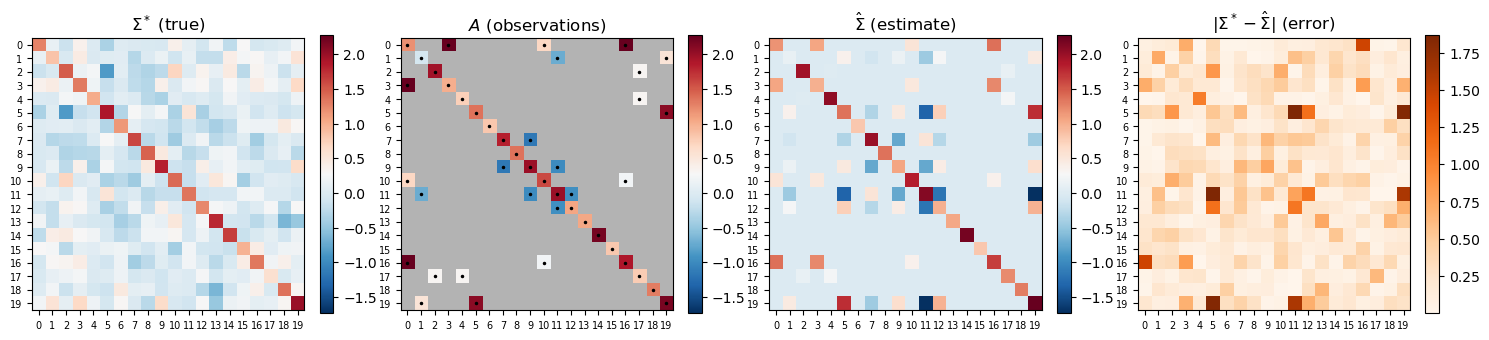

In [123]:
# Observed-entry mask (upper triangle for display)
obs_mask = np.zeros((d, d), dtype=bool)
obs_mask[inds[:, 0], inds[:, 1]] = True
obs_mask[inds[:, 1], inds[:, 0]] = True

vmin = min(Sigma_true.min(), Sigma_hat.min())
vmax = max(Sigma_true.max(), Sigma_hat.max())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))

titles  = [r"$\Sigma^*$ (true)", r"$A$ (observations)",
           r"$\hat\Sigma$ (estimate)", r"$|\Sigma^* - \hat\Sigma|$ (error)"]

# Panel 1: true covariance
im = axes[0].imshow(Sigma_true, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[0].set_title(titles[0])
plt.colorbar(im, ax=axes[0], fraction=0.046)

# Panel 2: observations — show only the observed entries; grey out the rest
A_display = np.full((d, d), np.nan)
A_display[obs_mask] = A[obs_mask]
axes[1].imshow(np.ones((d, d)), cmap='Greys', vmin=0, vmax=1, alpha=0.3)   # grey background
im2 = axes[1].imshow(A_display, vmin=vmin, vmax=vmax, cmap='RdBu_r')       # observed values
# Mark observed entries with a dot
for (i, j) in inds:
    axes[1].plot(j, i, 'k.', markersize=3)
    if i != j:
        axes[1].plot(i, j, 'k.', markersize=3)
axes[1].set_title(titles[1])
plt.colorbar(im2, ax=axes[1], fraction=0.046)

# Panel 3: estimate
im3 = axes[2].imshow(Sigma_hat, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[2].set_title(titles[2])
plt.colorbar(im3, ax=axes[2], fraction=0.046)

# Panel 4: absolute error
err = np.abs(Sigma_true - Sigma_hat)
im4 = axes[3].imshow(err, cmap='Oranges')
axes[3].set_title(titles[3])
plt.colorbar(im4, ax=axes[3], fraction=0.046)

for ax in axes:
    ax.set_xticks(range(d))
    ax.set_yticks(range(d))
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

## Per-iteration diagnostics

KKT residuals at final iterate:
  min eig X        = 9.998e-13   (≥ 0 required)
  min eig ∇f̃(X)    = -3.069e-07   (≥ 0 required)
  |⟨∇f̃(X), X⟩|     = 1.083e-06   (= 0 required)


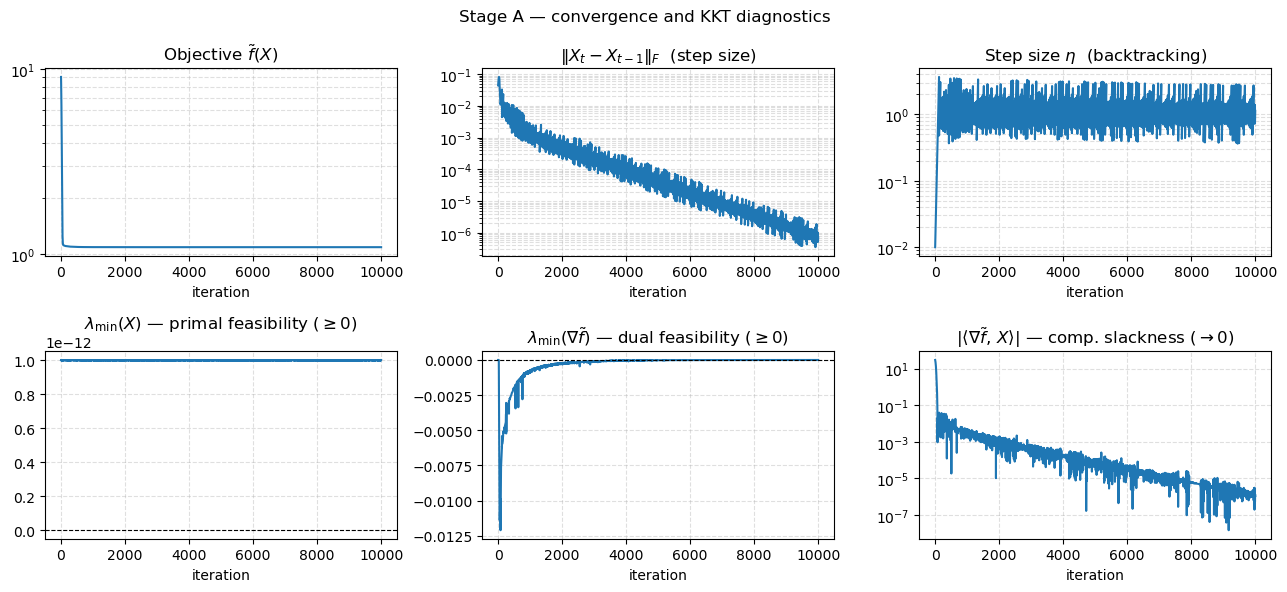

In [124]:
iters = range(len(hist_a))
obj        = [h['obj']        for h in hist_a]
delta      = [h['delta']      for h in hist_a]
eta_vals   = [h['eta']        for h in hist_a]
has_kkt    = 'min_eig_X' in hist_a[0]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
fig.suptitle("Stage A — convergence and KKT diagnostics", fontsize=12)

# ── top row: standard convergence ────────────────────────────────────────────
axes[0, 0].semilogy(iters, obj)
axes[0, 0].set_title("Objective $\\tilde{f}(X)$")

axes[0, 1].semilogy(iters, delta)
axes[0, 1].set_title(r"$\|X_t - X_{t-1}\|_F$  (step size)")

axes[0, 2].semilogy(iters, eta_vals)
axes[0, 2].set_title(r"Step size $\eta$  (backtracking)")

# ── bottom row: KKT residuals ─────────────────────────────────────────────────
if has_kkt:
    min_eig_X  = [h['min_eig_X']  for h in hist_a]
    min_eig_G  = [h['min_eig_G']  for h in hist_a]
    comp_slack = [h['comp_slack'] for h in hist_a]

    axes[1, 0].plot(iters, min_eig_X)
    axes[1, 0].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 0].set_title(r"$\lambda_{\min}(X)$ — primal feasibility ($\geq 0$)")

    axes[1, 1].plot(iters, min_eig_G)
    axes[1, 1].axhline(0, color='k', linewidth=0.8, linestyle='--')
    axes[1, 1].set_title(r"$\lambda_{\min}(\nabla\tilde{f})$ — dual feasibility ($\geq 0$)")

    axes[1, 2].semilogy(iters, np.maximum(comp_slack, 1e-16))
    axes[1, 2].set_title(r"$|\langle\nabla\tilde{f},\,X\rangle|$ — comp. slackness ($\to 0$)")

    print("KKT residuals at final iterate:")
    print(f"  min eig X        = {min_eig_X[-1]:.3e}   (≥ 0 required)")
    print(f"  min eig ∇f̃(X)    = {min_eig_G[-1]:.3e}   (≥ 0 required)")
    print(f"  |⟨∇f̃(X), X⟩|     = {comp_slack[-1]:.3e}   (= 0 required)")
else:
    for ax in axes[1]:
        ax.text(0.5, 0.5, "track_kkt=False", transform=ax.transAxes,
                ha='center', va='center', color='grey')

for ax in axes.flat:
    ax.set_xlabel("iteration")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

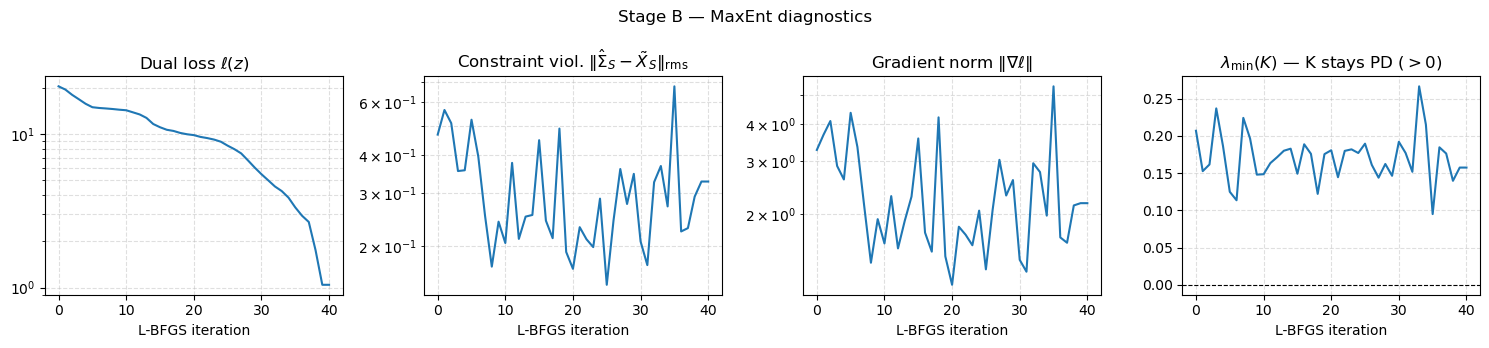

Stage B summary at convergence:
  log|Σ̂|  (entropy)   = -14.7385
  min eig K           = 1.57e-01
  constraint viol rms = 3.27e-01
  gradient norm       = 2.17e+00


In [125]:
iters_b = range(len(hist_b))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
fig.suptitle("Stage B — MaxEnt diagnostics", fontsize=12)

axes[0].semilogy(iters_b, [h['loss']            for h in hist_b])
axes[0].set_title(r"Dual loss $\ell(z)$")

axes[1].semilogy(iters_b, [h['constraint_viol'] for h in hist_b])
axes[1].set_title(r"Constraint viol. $\|\hat\Sigma_S - \tilde X_S\|_{\rm rms}$")

axes[2].semilogy(iters_b, [h['grad_norm']       for h in hist_b])
axes[2].set_title(r"Gradient norm $\|\nabla\ell\|$")

axes[3].plot(iters_b, [h['min_eig_K'] for h in hist_b])
axes[3].axhline(0, color='k', linewidth=0.8, linestyle='--')
axes[3].set_title(r"$\lambda_{\min}(K)$ — K stays PD ($> 0$)")

for ax in axes:
    ax.set_xlabel("L-BFGS iteration")
    ax.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Entropy is only meaningful at convergence (dual iterates are not primal-feasible)
logdet_Sigma_hat = np.linalg.slogdet(Sigma_hat)[1]
print("Stage B summary at convergence:")
print(f"  log|Σ̂|  (entropy)   = {logdet_Sigma_hat:.4f}")
print(f"  min eig K           = {hist_b[-1]['min_eig_K']:.2e}")
print(f"  constraint viol rms = {hist_b[-1]['constraint_viol']:.2e}")
print(f"  gradient norm       = {hist_b[-1]['grad_norm']:.2e}")